# Issue #13: Predictive Analytics – Problem Definition, Data Preparation and Baselines

**Input:** `feature_engineered_daily.csv`, `feature_dictionary.csv` (Issue #12)  
**Outputs (repository root):** `modelling_dataset.csv`, `backtest_windows.json`, `baseline_results.csv`, `baseline_metrics.csv`, `modelling_summary_i13.md`

**Rules**
- Predictors come only from `feature_engineering.PREDICTORS` (role `predictor`, known before the forecast day).
- Every evaluation is time-ordered: a model is trained only on days before the window it is tested on.
- Baselines are fixed before any model is fitted. Every number in the summary is generated from the outputs.

## 1. Business objective and prediction problem

**Question.** How many charging sessions will start at the Caltech site tomorrow?

| Item | Decision | Reason |
|---|---|---|
| Target | `session_count` per calendar day (local time) | Fully observed; directly usable for staffing and day-ahead energy planning; `total_kWh` kept as a secondary target |
| Unit / scope | One day, all chargers pooled | Single site; per-charger counts are too sparse |
| Horizon | Next day (t+1) | Predictors use only days up to t−1 |
| Metrics | MAE (sessions/day), RMSE, **WAPE**, bias | WAPE = total absolute error / total actual sessions. Demand levels differ by a factor of 5 between regimes, so absolute errors are not comparable across windows; WAPE is. MAPE is not used: it explodes on low-volume days |

**Data context (Issues #9–#11).** Four regimes: R1 free; R2 free with a 14 kWh default (from 1 Sep 2018); R3 paid (from 1 Nov 2018), with weekday volume roughly 55–60% lower; R4 COVID period (from mid-March 2020), with a collapse, a 106-day recording gap and a partial recovery. The modelling design is **one model for the whole period with regime flags** (`is_r2_policy`, `is_paid`, `is_covid`).

## 2. Evaluation design: backtest windows

A flag only helps once its regime has appeared in training. So the model is evaluated in several **backtest windows**, each in a different regime, and each trained only on the data before it:

| Window | Dates | Regime | What it tests |
|---|---|---|---|
| **W1** | Oct 2018 | R2 (free) | Forecasting under stable free charging |
| **W2** | Dec 2019 – Feb 2020 | R3 (paid) | Forecasting under stable paid charging, with a year of paid history |
| **W3** | Jun 2021 – end of data | R4 (recovery) | Forecasting a rising, post-closure demand, with the COVID period in training |
| S1 (stress) | Nov 2018 | first paid month | A rule change the model has never seen |
| S2 (stress) | 16 Mar – 30 Apr 2020 | first COVID weeks | A shock the model has never seen |

W1–W3 are the main evaluation (model selection in Issue #14 uses only cross-validation inside each window's training data). S1–S2 show what happens right after an unseen change; they are reported separately because no model can be expected to anticipate them.

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
import feature_engineering as fe

TARGET = "session_count"
daily = pd.read_csv(ROOT / "feature_engineered_daily.csv", parse_dates=["date"])
daily["holiday_name"] = daily["holiday_name"].fillna("")
dictionary = pd.read_csv(ROOT / "feature_dictionary.csv")
assert set(fe.PREDICTORS) <= set(dictionary.loc[dictionary.role == "predictor", "column"]), "predictor list and dictionary disagree"
print(f"{len(daily)} calendar days, {daily['date'].min().date()} to {daily['date'].max().date()}; "
      f"recording-gap days: {int(daily['in_collection_gap'].sum())}")

END = daily["date"].max()
WINDOWS = {
    "W1": {"start": "2018-10-01", "end": "2018-10-31", "kind": "main", "label": "Oct 2018, free (R2)"},
    "W2": {"start": "2019-12-01", "end": "2020-02-29", "kind": "main", "label": "Dec 2019 - Feb 2020, paid (R3)"},
    "W3": {"start": "2021-06-01", "end": str(END.date()), "kind": "main", "label": "Jun 2021 - end, recovery (R4)"},
    "S1": {"start": "2018-11-01", "end": "2018-11-30", "kind": "stress", "label": "Nov 2018, first paid month"},
    "S2": {"start": "2020-03-16", "end": "2020-04-30", "kind": "stress", "label": "16 Mar - 30 Apr 2020, first COVID weeks"},
}

1238 calendar days, 2018-04-25 to 2021-09-13; recording-gap days: 106


## 3. Modelling rows

In [2]:
usable = daily[daily[TARGET].notna() & daily[fe.PREDICTORS].notna().all(axis=1)].copy()
dropped = daily[~daily.index.isin(usable.index)]
print(f"Usable days: {len(usable)} of {len(daily)}. Not usable: {int(dropped['in_collection_gap'].sum())} recording-gap days and "
      f"{int((dropped['in_collection_gap'] == 0).sum())} days whose lags are not yet available (start of data, first days after the gap).")
usable.to_csv(ROOT / "modelling_dataset.csv", index=False)

rows = []
for w, cfg in WINDOWS.items():
    test = usable[(usable["date"] >= cfg["start"]) & (usable["date"] <= cfg["end"])]
    train = usable[usable["date"] < cfg["start"]]
    constant = [c for c in fe.PREDICTORS if train[c].nunique() <= 1]
    cfg["predictors"] = [c for c in fe.PREDICTORS if c not in constant]
    cfg["constant_in_train"] = constant
    rows.append({"window": w, "kind": cfg["kind"], "label": cfg["label"], "train_days": len(train),
                 "train_end": train["date"].max().date(), "test_days": len(test),
                 "test_start": test["date"].min().date(), "test_end": test["date"].max().date(),
                 "test_mean_sessions": test[TARGET].mean(), "major_holidays_in_test": int(test["is_major_holiday"].sum()),
                 "predictors": len(cfg["predictors"]), "constant_in_training (excluded)": ", ".join(constant) or "none"})
win_tab = pd.DataFrame(rows).set_index("window")
display(win_tab)

Usable days: 1104 of 1238. Not usable: 106 recording-gap days and 28 days whose lags are not yet available (start of data, first days after the gap).


,kind,label,train_days,train_end,test_days,test_start,test_end,test_mean_sessions,major_holidays_in_test,predictors,constant_in_training (excluded)
window,,,,,,,,,,,
W1,main,"Oct 2018, free (R2)",145,2018-09-30,31,2018-10-01,2018-10-31,78.064516,0,17,"is_paid, is_covid"
W2,main,"Dec 2019 - Feb 2020, paid (R3)",571,2019-11-30,91,2019-12-01,2020-02-29,25.450549,11,18,is_covid
W3,main,"Jun 2021 - end, recovery (R4)",999,2021-05-31,105,2021-06-01,2021-09-13,16.904762,2,19,none
S1,stress,"Nov 2018, first paid month",176,2018-10-31,30,2018-11-01,2018-11-30,43.500000,2,17,"is_paid, is_covid"
S2,stress,"16 Mar - 30 Apr 2020, first COVID weeks",677,2020-03-15,46,2020-03-16,2020-04-30,1.195652,0,18,is_covid


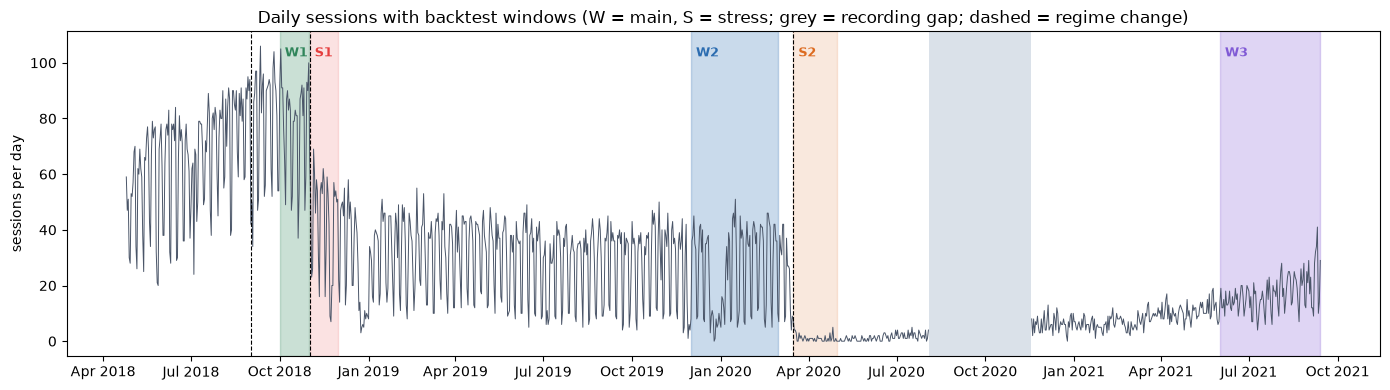

In [3]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily["date"], daily[TARGET], color="#4a5568", lw=0.7)
colors = {"W1": "#2f855a", "W2": "#2b6cb0", "W3": "#805ad5", "S1": "#e53e3e", "S2": "#dd6b20"}
for w, cfg in WINDOWS.items():
    ax.axvspan(pd.Timestamp(cfg["start"]), pd.Timestamp(cfg["end"]), color=colors[w], alpha=0.25 if cfg["kind"] == "main" else 0.15)
    ax.text(pd.Timestamp(cfg["start"]), ax.get_ylim()[1] * 0.95, " " + w, fontsize=9, va="top", color=colors[w], fontweight="bold")
for d in [fe.R2_START, fe.PAID_START, fe.COVID_START]:
    ax.axvline(d, color="k", ls="--", lw=0.8)
gap = daily[daily["in_collection_gap"] == 1]["date"]
if len(gap):
    ax.axvspan(gap.min(), gap.max(), color="#cbd5e0", alpha=0.7, lw=0)
ax.set(title="Daily sessions with backtest windows (W = main, S = stress; grey = recording gap; dashed = regime change)", ylabel="sessions per day")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

## 4. Baselines (fixed before any model is fitted)

| Baseline | Prediction | Why |
|---|---|---|
| `dow_mean_train` | Mean of the same weekday over all training days | The classic weekday baseline; shown to make clear why it fails when the level changes |
| `seasonal_naive_lag7` | Same weekday last week | Adapts to the current level immediately |
| `same_dow_mean_4w` | Mean of the same weekday over the last 4 weeks | Adapts to the level, less noisy than one week |

A model is only useful if it beats the **best adaptive baseline**, not just the training mean.

In [4]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": np.abs(e).sum() / y.sum(),
            "bias": e.mean(), "MedAE": np.median(np.abs(e)), "max_error": np.abs(e).max()}

def baselines(train, test):
    dow_mean = train.groupby("dayofweek")[TARGET].mean()
    return {"dow_mean_train": test["dayofweek"].map(dow_mean).values,
            "seasonal_naive_lag7": test["lag_7"].values,
            "same_dow_mean_4w": test["same_dow_mean_4w"].values}

res_rows, pred_frames = [], []
for w, cfg in WINDOWS.items():
    test = usable[(usable["date"] >= cfg["start"]) & (usable["date"] <= cfg["end"])]
    train = usable[usable["date"] < cfg["start"]]
    out = test[["date", TARGET, "dayofweek", "is_major_holiday", "holiday_name", "regime"]].copy(); out["window"] = w
    for b, p in baselines(train, test).items():
        out[f"pred_{b}"] = p
        res_rows.append({"window": w, "kind": cfg["kind"], "baseline": b, **metrics(test[TARGET], p)})
    pred_frames.append(out)
baseline_metrics = pd.DataFrame(res_rows)
baseline_results = pd.concat(pred_frames, ignore_index=True)
display(baseline_metrics.pivot(index="baseline", columns="window", values="WAPE").style.format("{:.1%}"))
best_base = {}
for w in WINDOWS:
    b = baseline_metrics[(baseline_metrics.window == w) & (baseline_metrics.baseline != "dow_mean_train")].sort_values("WAPE").iloc[0]
    best_base[w] = b["baseline"]
print("Best adaptive baseline per window:", best_base)

window,S1,S2,W1,W2,W3
baseline,,,,,
dow_mean_train,63.4%,3323.2%,11.9%,68.8%,71.9%
same_dow_mean_4w,49.4%,814.5%,9.6%,31.1%,21.4%
seasonal_naive_lag7,42.4%,301.8%,8.1%,32.8%,24.2%


Best adaptive baseline per window: {'W1': 'seasonal_naive_lag7', 'W2': 'same_dow_mean_4w', 'W3': 'same_dow_mean_4w', 'S1': 'seasonal_naive_lag7', 'S2': 'seasonal_naive_lag7'}


## 5. Predictor relationships (normal operation and all data)

,normal operation,all usable days
is_covid,NaN,-0.695
is_paid,-0.655,-0.586
is_r2_policy,-0.448,-0.435
is_weekend,-0.520,-0.307
dayofweek,-0.423,-0.247
dow_6,-0.346,-0.213
dow_5,-0.326,-0.183
is_major_holiday,-0.306,-0.178
dow_4,0.082,0.065
dow_3,0.139,0.072


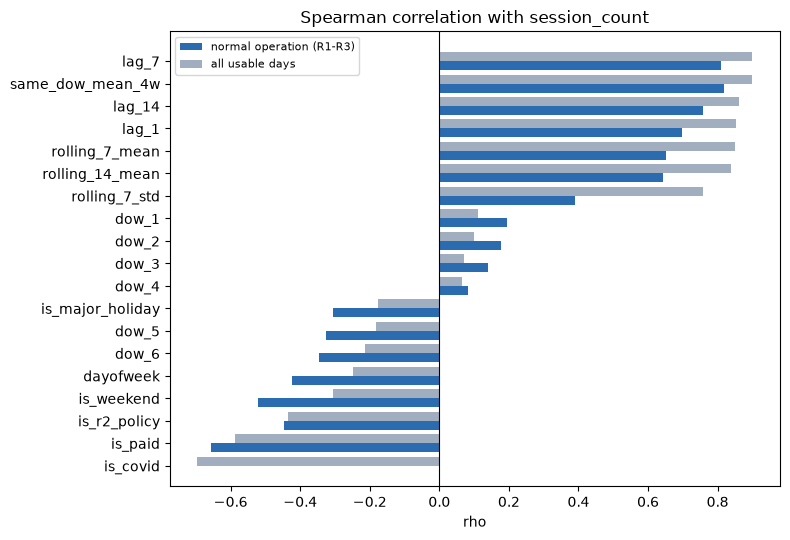

In [5]:
pre = usable[usable["date"] < fe.COVID_START]
corr = pd.DataFrame({
    "normal operation": pre[fe.PREDICTORS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET),
    "all usable days": usable[fe.PREDICTORS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)}).sort_values("all usable days")
display(corr.round(3))
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(corr))
ax.barh(y - 0.2, corr["normal operation"], 0.4, label="normal operation (R1-R3)", color="#2b6cb0")
ax.barh(y + 0.2, corr["all usable days"], 0.4, label="all usable days", color="#a0aec0")
ax.set_yticks(y); ax.set_yticklabels(corr.index); ax.axvline(0, color="k", lw=0.8)
ax.set(title="Spearman correlation with session_count", xlabel="rho"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Save outputs

In [6]:
baseline_results.to_csv(ROOT / "baseline_results.csv", index=False)
baseline_metrics.to_csv(ROOT / "baseline_metrics.csv", index=False)
config = {"target": TARGET, "all_predictors": fe.PREDICTORS, "windows": WINDOWS, "best_adaptive_baseline": best_base}
(ROOT / "backtest_windows.json").write_text(json.dumps(config, indent=2, default=str))
print("Saved modelling_dataset.csv, baseline_results.csv, baseline_metrics.csv, backtest_windows.json")

Saved modelling_dataset.csv, baseline_results.csv, baseline_metrics.csv, backtest_windows.json


## 7. Summary (generated)

In [7]:
bm = baseline_metrics.set_index(["window", "baseline"])
lines = [f"- **{w}** ({cfg['label']}): {win_tab.loc[w, 'test_days']} test days, mean {win_tab.loc[w, 'test_mean_sessions']:.1f} sessions/day, "
         f"{win_tab.loc[w, 'train_days']} training days. Best adaptive baseline `{best_base[w]}`: WAPE {bm.loc[(w, best_base[w]), 'WAPE']:.1%} "
         f"(MAE {bm.loc[(w, best_base[w]), 'MAE']:.1f}); training-mean weekday baseline: WAPE {bm.loc[(w, 'dow_mean_train'), 'WAPE']:.1%}."
         + (f" Excluded because constant in training: {', '.join(cfg['constant_in_train'])}." if cfg['constant_in_train'] else "")
         for w, cfg in WINDOWS.items()]
text = f"""# Issue #13 summary (generated from the data)

- **Target:** daily `session_count`, next-day horizon, all chargers pooled. Metrics: WAPE (comparable across regimes), MAE, RMSE, bias.
- **Data:** {len(usable)} usable days of {len(daily)} calendar days ({int(daily['in_collection_gap'].sum())} recording-gap days and {len(daily) - len(usable) - int(daily['in_collection_gap'].sum())} lag warm-up days excluded).
- **Design:** one model for the whole period with regime flags, evaluated in time-ordered backtest windows (main W1–W3, stress S1–S2).
- **Windows and baselines:**
""" + "\n".join(lines) + """
- **Reading the baselines:** the training-mean weekday baseline fails whenever the level has shifted since training (paid charging, COVID), so it is not a fair bar. Models in Issue #14 must beat the best *adaptive* baseline in each main window.
"""
(ROOT / "modelling_summary_i13.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# Issue #13 summary (generated from the data)

- **Target:** daily `session_count`, next-day horizon, all chargers pooled. Metrics: WAPE (comparable across regimes), MAE, RMSE, bias.
- **Data:** 1104 usable days of 1238 calendar days (106 recording-gap days and 28 lag warm-up days excluded).
- **Design:** one model for the whole period with regime flags, evaluated in time-ordered backtest windows (main W1–W3, stress S1–S2).
- **Windows and baselines:**
- **W1** (Oct 2018, free (R2)): 31 test days, mean 78.1 sessions/day, 145 training days. Best adaptive baseline `seasonal_naive_lag7`: WAPE 8.1% (MAE 6.4); training-mean weekday baseline: WAPE 11.9%. Excluded because constant in training: is_paid, is_covid.
- **W2** (Dec 2019 - Feb 2020, paid (R3)): 91 test days, mean 25.5 sessions/day, 571 training days. Best adaptive baseline `same_dow_mean_4w`: WAPE 31.1% (MAE 7.9); training-mean weekday baseline: WAPE 68.8%. Excluded because constant in training: is_covid.
- **W3** (Jun 2021 - end, recovery (R4)): 105 test days, mean 16.9 sessions/day, 999 training days. Best adaptive baseline `same_dow_mean_4w`: WAPE 21.4% (MAE 3.6); training-mean weekday baseline: WAPE 71.9%.
- **S1** (Nov 2018, first paid month): 30 test days, mean 43.5 sessions/day, 176 training days. Best adaptive baseline `seasonal_naive_lag7`: WAPE 42.4% (MAE 18.4); training-mean weekday baseline: WAPE 63.4%. Excluded because constant in training: is_paid, is_covid.
- **S2** (16 Mar - 30 Apr 2020, first COVID weeks): 46 test days, mean 1.2 sessions/day, 677 training days. Best adaptive baseline `seasonal_naive_lag7`: WAPE 301.8% (MAE 3.6); training-mean weekday baseline: WAPE 3323.2%. Excluded because constant in training: is_covid.
- **Reading the baselines:** the training-mean weekday baseline fails whenever the level has shifted since training (paid charging, COVID), so it is not a fair bar. Models in Issue #14 must beat the best *adaptive* baseline in each main window.
